# Competition and epistasis

In this notebook we will explore a simple model of gene epistasis and clonal competition in a tissue.

Models are built around two mutations that are common in the human aged oesophagus; loss of one or both copies of NOTCH1, which you fit in the earlier notebook. We will first simulate the two types of mutation in a model where mutations occur randomly over time but use the model to explore how *haploinsufficiency*- the sensitivity of cell phenotype (here fitness) to the loss of a single allele- alters the ability of a mutation to takeover the tissue.  

Our first models will treat the mutations as acting independently, and we will then go on to exploring the implications of *epistasis* between alleles- negative or positive synergistic effects arising from gene interactions.

In [1]:
from clone_competition_simulation.parameters import Parameters, TimeParameters, PopulationParameters, LabelParameters, FitnessParameters
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random
from collections import namedtuple
import matplotlib.cm as cm
from matplotlib.colors import Normalize


from clone_competition_simulation import (
    Gene,
    FitnessCalculator,
    FixedValue, 
    multiply_fitness,
    replace_fitness,
    PlottingParameters, 
    ColourRule, 
    PlotColourMaps,
    FeatureValue, 
    CloneFeature,
    EpistaticEffect
)

from clone_competition_simulation.plotting.animator import HexAnimator


## Parameters

Here we use parameters from previous publications that you should have (approximately) reproduced in the previous notebook. 

In [2]:
# Parameters
NOTCH1_HOM_FITNESS = 7.0
NOTCH1_HET_FITNESS = 2.3

DIVISION_RATE = 0.27
MUTATION_RATE = 0.000005
NUM_SIMS = 10
NUM_SAMPLES = 200
GRID_WIDTH = 1680
GRID_SIZE = GRID_WIDTH ** 2 #500 ** 2
MAX_TIME = 750 #5000

POPULATION_SIZE = 35

np.random.seed(0)


## Simulation functions

Here we will define different simulations with based on epistatic interactions between Notch1 single and double loss, and  haploinsufficiency. Our parameters are consistent with epistasis between copies of Notch1 (the fitness arising from the loss of a single gene is less than the square root of the loss of the both). To encode this we add a list of epistatic effects to the fitness calculator. 

We also include a function to the simulator to plot all fitnesses used in the model. This is important as its easy to miss individual combinations and get unexpected effects.

We've defined two functions, *sim_haplosufficient* and *sim_haploinsufficient*. The key difference between them is that in the haplosufficient case, the loss of a single copy has no effect. Whilst we know this is not correct, it is useful to examine the impact this would have on takeover when the double mutant fitness remains the same.

In [3]:
def sim_haplosufficient(cell_x, mutation_rate, max_time, plotInfo=PlottingParameters(figsize=None,plot_colour_maps=None)):
    
    alleles = [Gene(name='Notch1_allele1', mutation_distribution=FixedValue(1), synonymous_proportion=0),
               Gene(name='Notch1_allele2', mutation_distribution=FixedValue(1), synonymous_proportion=0),
              ]

    epistatics = [EpistaticEffect(name='Notch1_hom', gene_names=['Notch1_allele1', 'Notch1_allele2'], fitness_distribution=FixedValue(NOTCH1_HOM_FITNESS)),
                 ]

    fit_calc = FitnessCalculator(
        genes = alleles,
        combine_mutations = replace_fitness,
        epistatics = epistatics,
        multi_gene_array=True,
    )

    fitness_combinations = fit_calc.plot_fitness_combinations()
    print(f"Fitness combinations:  {fitness_combinations}")
    plt.show()

    initial_grid = np.zeros((cell_x,cell_x), dtype=int)
        
    p = Parameters(algorithm='WF2D', 
           population=PopulationParameters(initial_grid=initial_grid,cell_in_own_neighbourhood=True),
           times=TimeParameters(max_time=max_time, division_rate=DIVISION_RATE), 
           fitness=FitnessParameters(mutation_rates=mutation_rate,#0.01,
                                     fitness_calculator=fit_calc
                                    ),
           plotting=plotInfo

          )

    s = p.get_simulator()
    s.run_sim()
    return s

def sim_haploinsufficient(cell_x, mutation_rate, max_time, plotInfo=PlottingParameters(figsize=None,plot_colour_maps=None)):
    
    alleles = [Gene(name='Notch1_allele1', mutation_distribution=FixedValue(NOTCH1_HET_FITNESS), synonymous_proportion=0),
               Gene(name='Notch1_allele2', mutation_distribution=FixedValue(NOTCH1_HET_FITNESS), synonymous_proportion=0),
              ]

    epistatics = [EpistaticEffect(name='Notch1_hom', gene_names=['Notch1_allele1', 'Notch1_allele2'], fitness_distribution=FixedValue(NOTCH1_HOM_FITNESS)),
                 ]

    fit_calc = FitnessCalculator(
        genes = alleles,
        combine_mutations = replace_fitness,
        epistatics = epistatics,
        multi_gene_array=True,
    )

    fitness_combinations = fit_calc.plot_fitness_combinations()
    print(f"Fitness combinations:  {fitness_combinations}")
    plt.show()

    initial_grid = np.zeros((cell_x,cell_x), dtype=int)
        
    p = Parameters(algorithm='WF2D', 
           population=PopulationParameters(initial_grid=initial_grid,cell_in_own_neighbourhood=True),
           times=TimeParameters(max_time=max_time, division_rate=DIVISION_RATE), 
           fitness=FitnessParameters(mutation_rates=mutation_rate,#0.01,
                                     fitness_calculator=fit_calc
                                    ),
           plotting=plotInfo

          )

    s = p.get_simulator()
    s.run_sim()
    return s

*plot_genotype_takeover* is an LLM generated function that plots relative takeover of het and hom clones. There do not exist built in functions to achived this but from the github Claude proposed the function below.

*Task*- working from the function below and the original code in the github repository, *verify* that the code is sensible. In doing this, write notes on what the object *raw_fitness_array* contains and why this works.

*Task*- we will use the built in Muller plot code later in the practical, but this is normally unordered by genotype making the features see in *plot_genotype_takeover* less clear. Use an LLM of your choice to try generate functions that generate ordered Muller plots and Sankey plots to visualise the data in different ways. Verify each of them.

In [4]:
def plot_genotype_takeover(s):
    """
    Plot frequency over time of WT, Notch1_het (either allele), and Notch1_hom clones.
    """
    total_cells = s.population_array.shape[0]  # will use sum instead
    num_genes = len(s.fitness_calculator.genes) # self.fitness_calculator.num_genes # 2 (Notch1_allele1, Notch1_allele2)
    times = s.times
    n_timepoints = len(times)
    total_pop = s.initial_size_array.sum()  # constant population size

    # Classify each clone by genotype using raw_fitness_array
    # Columns: [0=WT_background, 1=Notch1_allele1, 2=Notch1_allele2, 3+=epistatic]
    ra = s.raw_fitness_array  # shape (n_clones, num_genes + n_epistatics + 1)

    has_a1 = ~np.isnan(ra[:, 1])  # allele1 mutated
    has_a2 = ~np.isnan(ra[:, 2])  # allele2 mutated

    idx_wt  = np.where(~has_a1 & ~has_a2)[0]
    idx_het = np.where( has_a1 ^  has_a2)[0]   # XOR: exactly one allele mutated
    idx_hom = np.where( has_a1 &  has_a2)[0]   # both alleles mutated

    # Convert sparse population_array to dense for summing
    pop = np.array(s.population_array.todense())  # shape (n_clones, n_timepoints)

    freq_wt  = pop[idx_wt,  :].sum(axis=0) / total_pop
    freq_het = pop[idx_het, :].sum(axis=0) / total_pop
    freq_hom = pop[idx_hom, :].sum(axis=0) / total_pop

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(times, freq_wt,  label='WT',          color='grey')
    ax.plot(times, freq_het, label='Notch1 het',  color='steelblue')
    ax.plot(times, freq_hom, label='Notch1 hom',  color='firebrick')
    ax.set_xlabel('Time (weeks)')
    ax.set_ylabel('Frequency')
    ax.set_ylim(0, 1)
    ax.legend()
    plt.tight_layout()
    return fig, ax

In [5]:
# This is a good location to store your new plotting functions

# YOUR CODE HERE 
raise NotImplementedError

# Testing

We will first run a short haploinsufficient simulation to check that everything works, and make some simple plots. We go on to run this for the lifetime of the experiment, visualising clonal takeover in different ways.

*Task*- repeat this for haplosufficient models. What are the key differences and what are the implications of haploinsufficiency for clonal takeover?

In [6]:
# Define the colour map. 
# We will see later how to assign different colour maps to different clones.
colour_rule = ColourRule(
    colourmap=cm.Reds
)
# And create a PlotColourMaps object using the colour rule
plot_colour_maps = PlotColourMaps(
    colour_rules=[colour_rule], 
    use_fitness=True
)

Fitness combinations:  Background                         1.0
Notch1_allele1                     2.3
Notch1_allele2                     2.3
Notch1_allele1 + Notch1_allele2    7.0
dtype: float64


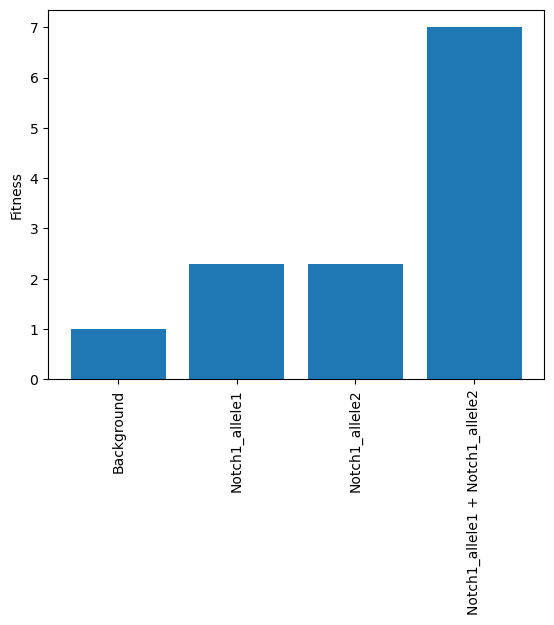

11:23:09 | DEBUG | Times rounded to match simulation steps:  Times used: [ 0.          3.7037037   7.40740741 11.11111111]


Output()

CPU times: user 153 ms, sys: 80.8 ms, total: 234 ms
Wall time: 627 ms


In [7]:
%%time

s = sim_haploinsufficient(10, 0.1,10)

In [8]:
s.times

array([ 0.        ,  3.7037037 ,  7.40740741, 11.11111111])

(0.0, 100.0)

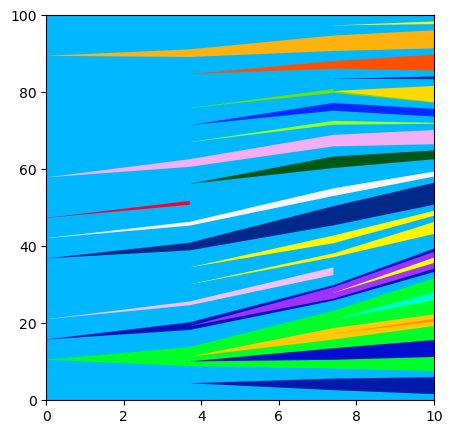

In [9]:
p = s.muller_plot(figsize=(5, 5), allow_y_extension=True, show_mutations_with_x=False);

p.set_ylim([0, 100])

(np.float64(-0.5), np.float64(10.00000001), np.float64(-0.5), np.float64(5.0))

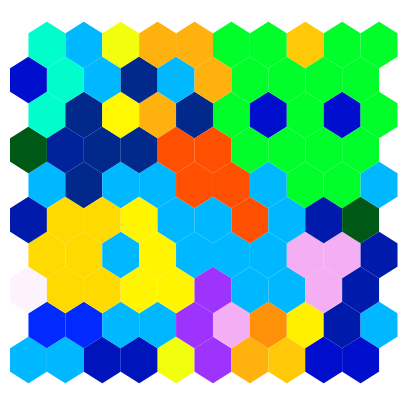

In [10]:
fig, ax = plt.subplots(figsize=(5, 5))
s.plot_grid(ax=ax)
ax.set_aspect('auto')  
plt.axis('off')

Fitness combinations:  Background                         1.0
Notch1_allele1                     2.3
Notch1_allele2                     2.3
Notch1_allele1 + Notch1_allele2    7.0
dtype: float64


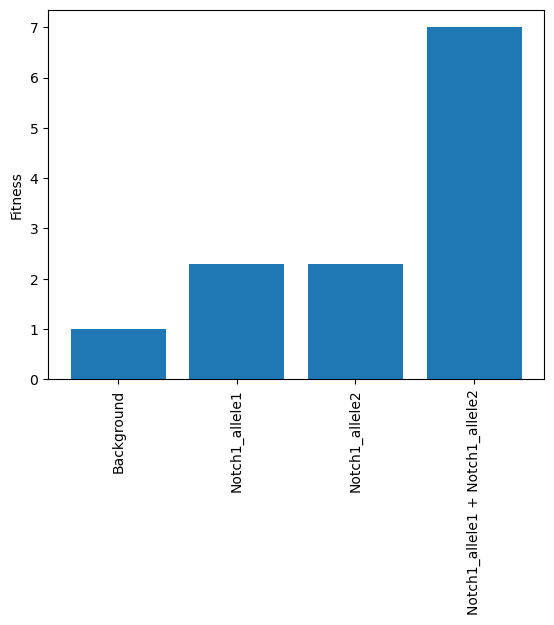

12:09:46 | DEBUG | Times rounded to match simulation steps:  Times used: [  0.           7.40740741  14.81481481  22.22222222  29.62962963
  37.03703704  44.44444444  51.85185185  59.25925926  66.66666667
  74.07407407  81.48148148  88.88888889  96.2962963  103.7037037
 111.11111111 118.51851852 125.92592593 133.33333333 140.74074074
 148.14814815 155.55555556 162.96296296 170.37037037 177.77777778
 185.18518519 196.2962963  203.7037037  211.11111111 218.51851852
 225.92592593 233.33333333 240.74074074 248.14814815 255.55555556
 262.96296296 270.37037037 277.77777778 285.18518519 292.59259259
 300.         307.40740741 314.81481481 322.22222222 329.62962963
 337.03703704 344.44444444 351.85185185 359.25925926 366.66666667
 374.07407407 381.48148148 388.88888889 396.2962963  403.7037037
 411.11111111 418.51851852 425.92592593 433.33333333 440.74074074
 448.14814815 455.55555556 462.96296296 470.37037037 477.77777778
 485.18518519 492.59259259 500.         507.40740741 514.81481481
 522.

Output()

In [39]:
s = sim_haploinsufficient(GRID_WIDTH, MUTATION_RATE,MAX_TIME, PlottingParameters(plot_colour_maps=plot_colour_maps))

In [40]:
print(s.view_clone_info(include_raw_fitness=True))

      clone id  label  fitness  generation born  parent clone id  \
0            0      0      1.0                0               -1   
1            1      0      2.3                1                0   
2            2      0      2.3                1                0   
3            3      0      2.3                1                0   
4            4      0      2.3                1                0   
...        ...    ...      ...              ...              ...   
2782      2782      0      7.0              100             1202   
2783      2783      0      7.0              100              597   
2784      2784      0      2.3              100               27   
2785      2785      0      7.0              100             2412   
2786      2786      0      7.0              100              800   

     last gene mutated  Initial clone fitness  Notch1_allele1  Notch1_allele2  \
0                 None                    1.0             NaN             NaN   
1       Notch1_allele

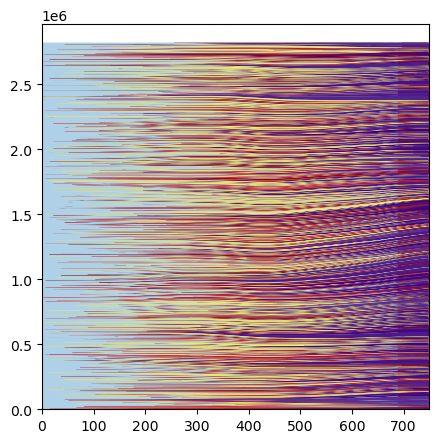

In [41]:
p = s.muller_plot(figsize=(5, 5), allow_y_extension=True, show_mutations_with_x=False);


(np.float64(-0.5),
 np.float64(1680.00000168),
 np.float64(-0.5),
 np.float64(840.0))

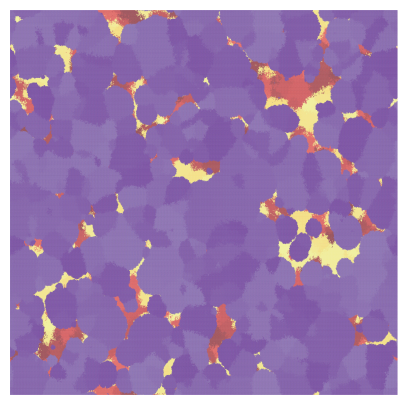

In [42]:
fig, ax = plt.subplots(figsize=(5, 5))
s.plot_grid(ax=ax)
ax.set_aspect('auto')  
plt.axis('off')

In [43]:
rules = [
    ColourRule(  # No genes mutated, light blue colour
        rule_filter=[ 
                FeatureValue(  
                    clone_feature=CloneFeature.GENES_MUTATED,   
                    value=set()  # Empty set for "no genes mutated"
            )
        ], 
        colourmap=cm.ScalarMappable(norm=Normalize(vmin=0, vmax=2), cmap=cm.Blues).to_rgba
    ), 
    ColourRule(  # First gene mutated, dark Red
        rule_filter=[ 
                FeatureValue(  
                    clone_feature=CloneFeature.GENES_MUTATED,   
                    value="Notch1_allele1"   # This will not match clones if other genes are mutated too! 
            )
        ], 
        colourmap=cm.ScalarMappable(norm=Normalize(vmin=-2, vmax=1), cmap=cm.Reds).to_rgba,
    ),
    ColourRule(  # Second gene mutated, yellow
        rule_filter=[ 
                FeatureValue(  
                    clone_feature=CloneFeature.GENES_MUTATED,   
                    value="Notch1_allele2"
            )
        ], 
        colourmap=cm.ScalarMappable(norm=Normalize(vmin=-20, vmax=2), cmap=cm.inferno).to_rgba,
    ), 
    ColourRule(  # Both genes mutated, purple
        rule_filter=[ 
                FeatureValue(  
                    clone_feature=CloneFeature.GENES_MUTATED,   
                    value={"Notch1_allele1", "Notch1_allele2"}  # This will match clones with both Gene1 and Gene2 mutated
            )
        ], 
        colourmap=cm.ScalarMappable(norm=Normalize(vmin=-5, vmax=1), cmap=cm.Purples).to_rgba
    )
]


plot_colour_maps = PlotColourMaps(
    colour_rules=rules
)

Fitness combinations:  Background                         1.0
Notch1_allele1                     2.3
Notch1_allele2                     2.3
Notch1_allele1 + Notch1_allele2    7.0
dtype: float64


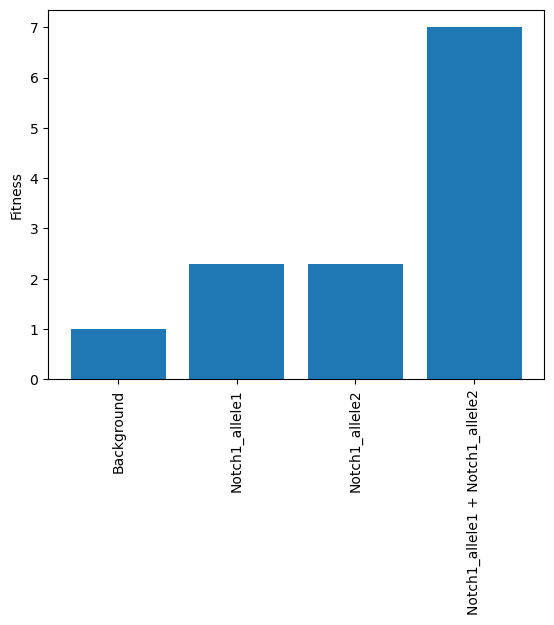

12:17:33 | DEBUG | Times rounded to match simulation steps:  Times used: [  0.           7.40740741  14.81481481  22.22222222  29.62962963
  37.03703704  44.44444444  51.85185185  59.25925926  66.66666667
  74.07407407  81.48148148  88.88888889  96.2962963  103.7037037
 111.11111111 118.51851852 125.92592593 133.33333333 140.74074074
 148.14814815 155.55555556 162.96296296 170.37037037 177.77777778
 185.18518519 196.2962963  203.7037037  211.11111111 218.51851852
 225.92592593 233.33333333 240.74074074 248.14814815 255.55555556
 262.96296296 270.37037037 277.77777778 285.18518519 292.59259259
 300.         307.40740741 314.81481481 322.22222222 329.62962963
 337.03703704 344.44444444 351.85185185 359.25925926 366.66666667
 374.07407407 381.48148148 388.88888889 396.2962963  403.7037037
 411.11111111 418.51851852 425.92592593 433.33333333 440.74074074
 448.14814815 455.55555556 462.96296296 470.37037037 477.77777778
 485.18518519 492.59259259 500.         507.40740741 514.81481481
 522.

Output()

In [44]:
insufficient = sim_haploinsufficient(GRID_WIDTH, MUTATION_RATE,MAX_TIME, PlottingParameters(plot_colour_maps=plot_colour_maps))

(np.float64(-0.5),
 np.float64(1680.00000168),
 np.float64(-0.5),
 np.float64(840.0))

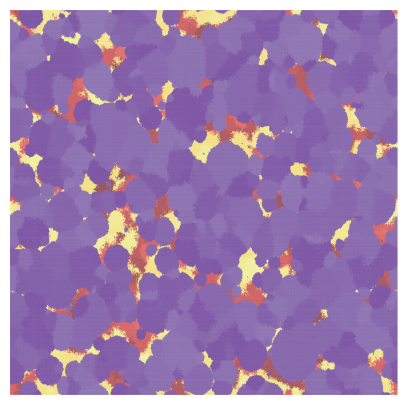

In [45]:
fig, ax = plt.subplots(figsize=(5, 5))
insufficient.plot_grid(ax=ax)
ax.set_aspect('auto')  
plt.axis('off')

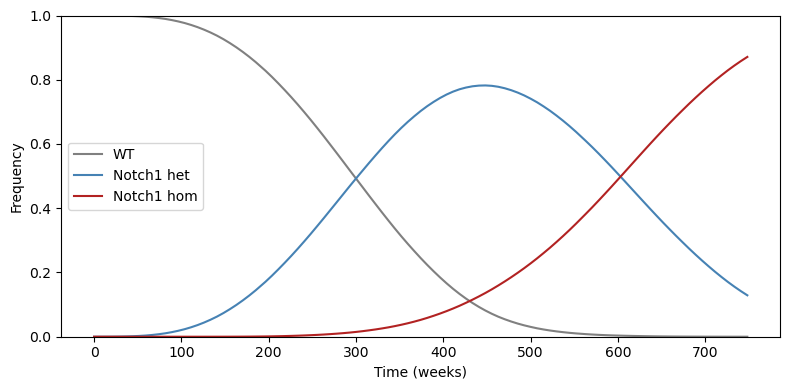

In [46]:
fig, ax = plot_genotype_takeover(insufficient)
plt.show()

Fitness combinations:  Background                         1.0
Notch1_allele1                     1.0
Notch1_allele2                     1.0
Notch1_allele1 + Notch1_allele2    7.0
dtype: float64


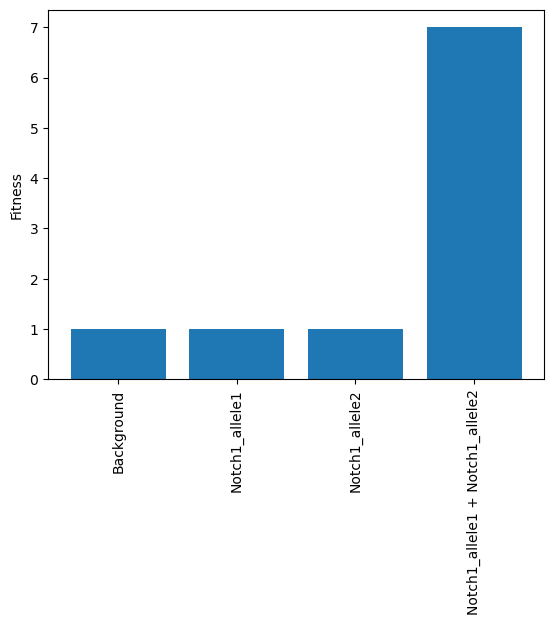

12:24:14 | DEBUG | Times rounded to match simulation steps:  Times used: [  0.           7.40740741  14.81481481  22.22222222  29.62962963
  37.03703704  44.44444444  51.85185185  59.25925926  66.66666667
  74.07407407  81.48148148  88.88888889  96.2962963  103.7037037
 111.11111111 118.51851852 125.92592593 133.33333333 140.74074074
 148.14814815 155.55555556 162.96296296 170.37037037 177.77777778
 185.18518519 196.2962963  203.7037037  211.11111111 218.51851852
 225.92592593 233.33333333 240.74074074 248.14814815 255.55555556
 262.96296296 270.37037037 277.77777778 285.18518519 292.59259259
 300.         307.40740741 314.81481481 322.22222222 329.62962963
 337.03703704 344.44444444 351.85185185 359.25925926 366.66666667
 374.07407407 381.48148148 388.88888889 396.2962963  403.7037037
 411.11111111 418.51851852 425.92592593 433.33333333 440.74074074
 448.14814815 455.55555556 462.96296296 470.37037037 477.77777778
 485.18518519 492.59259259 500.         507.40740741 514.81481481
 522.

Output()

In [47]:
sufficient = sim_haplosufficient(GRID_WIDTH, MUTATION_RATE,MAX_TIME, PlottingParameters(plot_colour_maps=plot_colour_maps))

(np.float64(-0.5),
 np.float64(1680.00000168),
 np.float64(-0.5),
 np.float64(840.0))

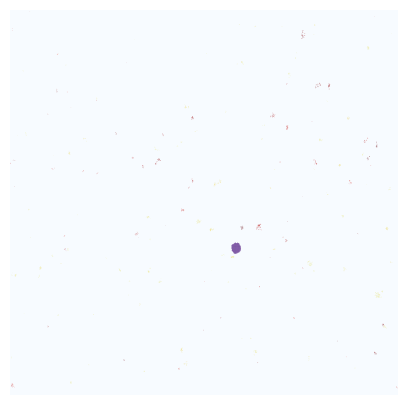

In [48]:
fig, ax = plt.subplots(figsize=(5, 5))
sufficient.plot_grid(ax=ax)
ax.set_aspect('auto')  
plt.axis('off')

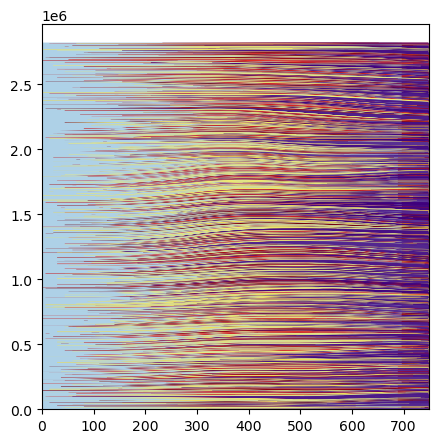

In [49]:
p = s.muller_plot(figsize=(5, 5), allow_y_extension=True, show_mutations_with_x=False);



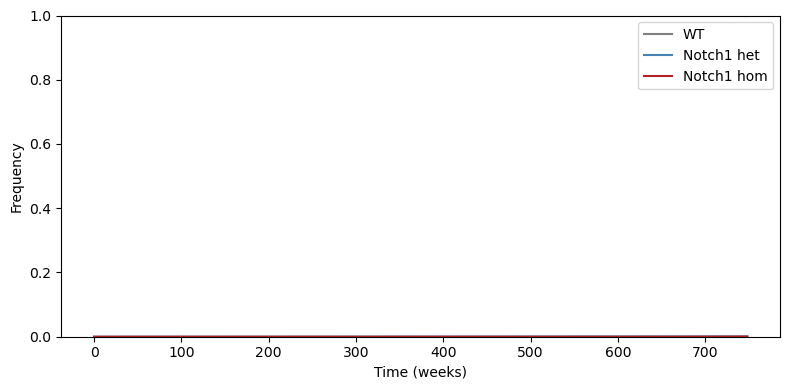

In [50]:
fig, ax = plot_genotype_takeover(sufficient)
plt.show()

*Task- create a version of the simulation code where Notch1 alleles have no epistasis. How is the result different?*

In [53]:
# YOUR CODE HERE 
raise NotImplementedError

*Task- below is a model of Notch1/Notch2/Trp53 dynamics taken from a recent paper. Use the different plotting methods to explore its dynamics. Alter different parameters to see how variation in gene fitness, mutation rate etc can change the outputs*

In [57]:
# Parameters
NOTCH1_HOM_FITNESS = 7.0

NOTCH1_HET_FITNESS = 2.3
NOTCH2_FITNESS = 1.0
TRP53_FITNESS = 1.6 # taken from inference from TP53 early takeover - note that it varies

NOTCH2_NOTCH1_HET_FITNESS = NOTCH1_HET_FITNESS * 1.1 # estimated from single timepoint takeover 
NOTCH2_NOTCH1_HOM_FITNESS = NOTCH1_HOM_FITNESS * 1.1
NOTCH2_TRP53_FITNESS = TRP53_FITNESS


DIVISION_RATE = 0.27
MUTATION_RATE = 0.000005
NUM_SIMS = 10
NUM_SAMPLES = 200
GRID_WIDTH = 1680
GRID_SIZE = GRID_WIDTH ** 2 #500 ** 2
MAX_TIME = 750 #5000

POPULATION_SIZE = 35

np.random.seed(0)

def sim(cell_x, mutation_rate, max_time, plotInfo=PlottingParameters(figsize=None,plot_colour_maps=None)):
    
    alleles = [Gene(name='Notch1_allele1', mutation_distribution=FixedValue(NOTCH1_HET_FITNESS), synonymous_proportion=0),
               Gene(name='Notch1_allele2', mutation_distribution=FixedValue(NOTCH1_HET_FITNESS), synonymous_proportion=0),
               Gene(name='Notch2', mutation_distribution=FixedValue(NOTCH2_FITNESS), synonymous_proportion=0),
               Gene(name='Trp53', mutation_distribution=FixedValue(TRP53_FITNESS), synonymous_proportion=0)
              ]

    epistatics = [EpistaticEffect(name='Notch1_hom', gene_names=['Notch1_allele1', 'Notch1_allele2'], fitness_distribution=FixedValue(NOTCH1_HOM_FITNESS)),
                  EpistaticEffect(name='Trp53_Notch1_het1', gene_names=['Notch1_allele1', 'Trp53'], fitness_distribution=FixedValue(NOTCH1_HET_FITNESS)),
                  EpistaticEffect(name='Trp53_Notch1_het2', gene_names=['Notch1_allele2', 'Trp53'], fitness_distribution=FixedValue(NOTCH1_HET_FITNESS)),
                  EpistaticEffect(name='Notch2_Notch1_het1', gene_names=['Notch1_allele1', 'Notch2'], fitness_distribution=FixedValue(NOTCH2_NOTCH1_HET_FITNESS)),
                  EpistaticEffect(name='Notch2_Notch1_het2', gene_names=['Notch1_allele2', 'Notch2'], fitness_distribution=FixedValue(NOTCH2_NOTCH1_HET_FITNESS)),
                  EpistaticEffect(name='Notch2_Trp53', gene_names=['Notch2', 'Trp53'], fitness_distribution=FixedValue(NOTCH2_TRP53_FITNESS)),
                  
                  EpistaticEffect(name='Trp53_Notch1_hom', gene_names=['Notch1_allele1', 'Notch1_allele2', 'Trp53'], fitness_distribution=FixedValue(NOTCH1_HOM_FITNESS)),
                  EpistaticEffect(name='Notch2_Notch1_hom', gene_names=['Notch1_allele1', 'Notch1_allele2', 'Notch2'], fitness_distribution=FixedValue(NOTCH2_NOTCH1_HOM_FITNESS)),
                  EpistaticEffect(name='Notch2_Trp53_Notch1_het1', gene_names=['Notch1_allele1', 'Notch2', 'Trp53'], fitness_distribution=FixedValue(NOTCH2_NOTCH1_HET_FITNESS)),
                  EpistaticEffect(name='Notch2_Trp53_Notch1_het2', gene_names=['Notch1_allele2', 'Notch2', 'Trp53'], fitness_distribution=FixedValue(NOTCH2_NOTCH1_HET_FITNESS)),
                  
                  EpistaticEffect(name='Notch2_Trp53_Notch1_hom', gene_names=['Notch1_allele1', 'Notch1_allele2', 'Notch2', 'Trp53'], fitness_distribution=FixedValue(NOTCH2_NOTCH1_HOM_FITNESS))
                 ]

    fit_calc = FitnessCalculator(
        genes = alleles,
        combine_mutations = replace_fitness,
        #combine_array="priority",
        epistatics = epistatics,
        multi_gene_array=True,
    )

    fitness_combinations = fit_calc.plot_fitness_combinations()
    print(f"Fitness combinations:  {fitness_combinations}")
    plt.show()

    initial_grid = np.zeros((cell_x,cell_x), dtype=int)
        
    p = Parameters(algorithm='WF2D', 
           population=PopulationParameters(initial_grid=initial_grid,cell_in_own_neighbourhood=True),
           times=TimeParameters(max_time=max_time, division_rate=DIVISION_RATE), 
           fitness=FitnessParameters(mutation_rates=mutation_rate,#0.01,
                                     fitness_calculator=fit_calc
                                    ),
           #plotting=plotInfo

          )

    s = p.get_simulator()
    s.run_sim()
    return s

Fitness combinations:  Background                                          1.00
Notch1_allele1                                      2.30
Notch1_allele2                                      2.30
Notch1_allele1 + Notch1_allele2                     7.00
Notch2                                              1.00
Notch1_allele1 + Notch2                             2.53
Notch1_allele2 + Notch2                             2.53
Notch1_allele1 + Notch1_allele2 + Notch2            7.70
Trp53                                               1.60
Notch1_allele1 + Trp53                              2.30
Notch1_allele2 + Trp53                              2.30
Notch1_allele1 + Notch1_allele2 + Trp53             7.00
Notch2 + Trp53                                      1.60
Notch1_allele1 + Notch2 + Trp53                     2.53
Notch1_allele2 + Notch2 + Trp53                     2.53
Notch1_allele1 + Notch1_allele2 + Notch2 + Trp53    7.70
dtype: float64


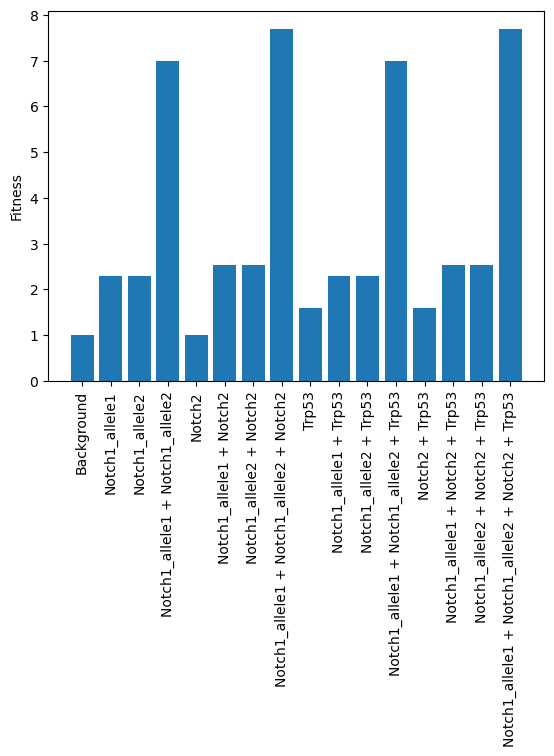

12:37:48 | DEBUG | Times rounded to match simulation steps:  Times used: [  0.           7.40740741  14.81481481  22.22222222  29.62962963
  37.03703704  44.44444444  51.85185185  59.25925926  66.66666667
  74.07407407  81.48148148  88.88888889  96.2962963  103.7037037
 111.11111111 118.51851852 125.92592593 133.33333333 140.74074074
 148.14814815 155.55555556 162.96296296 170.37037037 177.77777778
 185.18518519 196.2962963  203.7037037  211.11111111 218.51851852
 225.92592593 233.33333333 240.74074074 248.14814815 255.55555556
 262.96296296 270.37037037 277.77777778 285.18518519 292.59259259
 300.         307.40740741 314.81481481 322.22222222 329.62962963
 337.03703704 344.44444444 351.85185185 359.25925926 366.66666667
 374.07407407 381.48148148 388.88888889 396.2962963  403.7037037
 411.11111111 418.51851852 425.92592593 433.33333333 440.74074074
 448.14814815 455.55555556 462.96296296 470.37037037 477.77777778
 485.18518519 492.59259259 500.         507.40740741 514.81481481
 522.

Output()

In [59]:
complexGRN = sim(GRID_WIDTH, MUTATION_RATE,MAX_TIME)